# Figure 3

Panels G–K: natural-movie frames, luminance trace and network outputs of three OFF-medulla pairs, $R^2$ of every lamina and medulla pair per video, and same- versus combined-polarity $R^2$. Also Fig. S4: sampled pixel locations.

**Data.** Ten videos of the Chicago Motion Database (https://cmd.rcc.uchicago.edu/; Salisbury & Palmer, *J. Stat. Phys.* 162 (2016)). The notebook reads the luminance traces extracted from them (Methods): `TracesNatural<video>_live.txt` and `TracePixelMeta.npz` in `PATH_TRACES`, and video frames, `MovieFrames_full.npz`, in `PATH_MOVIES`.

**Precomputed.** $R^2$ of every pair for the 30 filters per type and the ten videos (`r2_<key>.pkl` in `PATH_R2_CACHE`; recomputed by this notebook if missing), and the analytic SNR of the pairs, which sets the order of panels I and J as in Fig. 3B, C (`PrecomputedSNR/`).

**SNR code.** All functions to compute the SNR (Eqs. 20, 21) are in `Fig3_1_SNR_vs_TemporalDiversity.ipynb`, which writes the files of `PrecomputedSNR/` if they are missing.

**Fit parameters.** `FitParameters/` contains the 30 filters per cell type.

In [1]:
import colorsys
import hashlib
import pickle
import re
from itertools import combinations_with_replacement
from pathlib import Path

import numpy as np
import scipy.signal as signal
from scipy.interpolate import interp1d
from scipy.stats import wilcoxon
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch

matplotlib.rcParams['font.family']       = 'sans-serif'
matplotlib.rcParams['font.sans-serif']   = ['Arial']
matplotlib.rcParams['font.size']         = 12
matplotlib.rcParams['axes.titlesize']    = 12
matplotlib.rcParams['axes.labelsize']    = 12
matplotlib.rcParams['xtick.labelsize']   = 12
matplotlib.rcParams['ytick.labelsize']   = 12
matplotlib.rcParams['legend.fontsize']   = 12
matplotlib.rcParams['pdf.fonttype']      = 42
matplotlib.rcParams['ps.fonttype']       = 42
matplotlib.rcParams['mathtext.fontset']  = 'custom'
matplotlib.rcParams['mathtext.rm']       = 'Arial'
matplotlib.rcParams['mathtext.it']       = 'Arial:italic'
matplotlib.rcParams['axes.spines.top']   = False
matplotlib.rcParams['axes.spines.right'] = False

# Paths
PATH_MOVIES    = Path('/Users/luisaramirez/Documents/Documentos/PostDoc/Mainz_Sillies/Research/'
                      'Julijana_Marion/Research/Codes/Optimization/NaturalVideo')
PATH_TRACES    = PATH_MOVIES / 'Traces_flysigma'
PATH_R2_CACHE  = Path('/Users/luisaramirez/Documents/Documentos/PostDoc/Mainz_Sillies/Research/'
                      'Julijana_Marion/Research/Codes/Optimization/PNAS_revisions/'
                      'NatMovies_simulations/_jointdecoder_cache')
PATH_SNR_CACHE = Path('PrecomputedSNR')
PATH_PARAMS    = Path('FitParameters')
PATH_PDF       = Path('Pdf_figures')
PATH_PDF.mkdir(exist_ok=True)

In [2]:
COLOR_REF = {'blue': '#1c75bc', 'red': '#ef4237',
             'green': '#808233', 'yellow': '#f6eb16', 'orange': '#faa51a'}


def shade(hex_color, factor, dhue=0.0):
    r, g, b = matplotlib.colors.to_rgb(hex_color)
    h, l, s = colorsys.rgb_to_hls(r, g, b)
    return colorsys.hls_to_rgb((h + dhue / 360.0) % 1.0, float(np.clip(l * factor, 0.05, 0.88)), s)


COLOR_PATHWAY  = {'Lamina': COLOR_REF['green'], 'ON Medulla': COLOR_REF['yellow'],
                  'OFF Medulla': COLOR_REF['orange']}
COLOR_POLARITY = {'double': COLOR_REF['blue'], 'single': COLOR_REF['red']}
COLOR_CLASS    = {'D': COLOR_REF['blue'], 'S': COLOR_REF['red'], 'C': '#984ea3'}
CLASS_NAME     = {'D': 'Double', 'S': 'Single', 'C': 'Combined'}
C_TRACE_STIM   = 'k'
C_TRACE_OUT    = shade(COLOR_REF['orange'], 0.85)

CIRCUITS  = {'Lamina':      ['L1', 'L2', 'L3'],
             'ON Medulla':  ['Mi1', 'Mi9', 'Tm3', 'Mi4'],
             'OFF Medulla': ['Tm2', 'Tm1', 'Tm4', 'Tm9']}
ALL_NAMES = [n for ns in CIRCUITS.values() for n in ns]
DOUBLE_POLARITY = ['L1', 'L2', 'Mi1', 'Tm3', 'Tm1', 'Tm2', 'Tm4']
POLARITY_OF     = {n: ('double' if n in DOUBLE_POLARITY else 'single') for n in ALL_NAMES}

PAIRS     = {c: ['-'.join(p) for p in combinations_with_replacement(ns, 2)]
             for c, ns in CIRCUITS.items()}
ALL_PAIRS = [(c, l) for c in CIRCUITS for l in PAIRS[c]]      # 6 + 10 + 10 = 26
IDX       = {k: i for i, k in enumerate(ALL_PAIRS)}


def pol_class(label):
    # 'D' both double, 'S' both single, 'C' combined, 'R' redundant (one type twice)
    names = label.split('-')
    if len(set(names)) == 1:
        return 'R'
    classes = {'D' if nm in DOUBLE_POLARITY else 'S' for nm in names}
    return classes.pop() if len(classes) == 1 else 'C'


def split_name(ct):
    m = re.match(r'([A-Za-z]+)(\d+)', ct)
    return m.group(1), int(m.group(2))


def pair_tokens(label):
    # canonical order, shared prefix written once: {L1, L3} -> ('L1', 'L1'), ('3', 'L3')
    a, b = sorted(label.split('-'), key=split_name)
    pa, pb = split_name(a)[0], split_name(b)[0]
    return (a, a), ((b[len(pb):] if pa == pb else b), b)


def label_tokens(label):
    (ta, na), (tb, nb) = pair_tokens(label)
    return [(ta, COLOR_POLARITY[POLARITY_OF[na]]), ('|', 'k'),
            (tb, COLOR_POLARITY[POLARITY_OF[nb]])]

In [3]:
DT_FIXED   = 0.01                     # s, resampling step
K_LAGS     = 100                      # decoder window: K_LAGS * DT_FIXED = 1 s
LAGS_DEC   = -np.arange(K_LAGS)
T_SKIP     = 1.0                      # s of transient dropped from every trace
TRAIN_FRAC = 0.7
REG        = 10.0                     # ridge penalty
SEED       = 0
SIGMA_IN   = 0.0                      # no input noise
RESP_RATIO = 0.0343621                # sigma_N^2 / var(response)

GEN_FILTERS = PATH_PARAMS / 'GeneratedFilters_Inverse_UnconstrainedFit_GaussianDistributed.txt'


def filter_function(t, tau1, tau2, rho_):
    # Eq. 4 with beta1 = 4, beta2 = 3 and rho = rho_ - 1, peak-normalized
    rho = rho_ - 1
    h = t**3 * (np.exp(-t / tau1) / tau1**4) + t**2 * (rho * np.exp(-t / tau2) / tau2**3)
    return h / np.max(np.abs(h))


ENS = {}
with open(GEN_FILTERS) as fh:
    for line in fh:
        if line.strip() and not line.lstrip().startswith('#'):
            F = line.split()
            ENS.setdefault(F[0], []).append(tuple(float(f) for f in F[6:9]))   # tau1, tau2, rho_
N_REAL = len(ENS[ALL_NAMES[0]])

META     = np.load(PATH_TRACES / 'TracePixelMeta.npz', allow_pickle=True)
MOVIES   = [str(m) for m in META['movies']]
N_MOVIES = len(MOVIES)
N_PIX    = int(META['n_pix'])                                          # 200 locations per video
T_MAX    = np.array([float(META[f'{m}|duration']) for m in MOVIES])   # s
TRACE_TIMEBASE = 1.0 * N_PIX                                           # real time


def load_luminance(i_movie):
    # the traces of one video concatenated, resampled at DT_FIXED; 'stim' is z-scored
    span  = T_MAX[i_movie] * TRACE_TIMEBASE
    raw   = np.loadtxt(PATH_TRACES / ('TracesNatural' + MOVIES[i_movie] + '_live.txt'))
    raw   = np.reshape(np.transpose(raw), -1)
    T_arr = np.linspace(0, span, raw.size)
    cut   = np.where(T_arr >= span)[0][0]
    raw, T_arr = raw[:cut], T_arr[:cut]

    n_t   = int(T_arr[-1] / DT_FIXED)
    t_sig = np.arange(n_t) * DT_FIXED
    resampled = interp1d(T_arr, raw, kind='linear', fill_value='extrapolate')(t_sig)

    skip  = int(T_SKIP / DT_FIXED)
    stim  = resampled[skip:] - resampled[skip:].mean()
    return dict(t=t_sig, raw=resampled, stim=stim / stim.std(), n_t=n_t, skip=skip)


MOVIE_CACHE = {i: load_luminance(i) for i in range(N_MOVIES)}

In [4]:
def build_lag_matrix(s, lags, out):
    T = len(s)
    out[:] = 0.0
    for i, lag in enumerate(lags):
        if   lag > 0: out[lag:, i] = s[:T - lag]
        elif lag < 0: out[:lag, i] = s[-lag:]
        else:         out[:, i]    = s
    return out


def train_test_split(channels, target, lags):
    K = len(lags)
    S = np.empty((len(target), K * len(channels)))
    for j, ch in enumerate(channels):
        build_lag_matrix(ch, lags, out=S[:, j * K:(j + 1) * K])
    t0, t1 = max(0, int(lags.max())), min(len(target), len(target) + int(lags.min()))
    S, y   = S[t0:t1], np.asarray(target)[t0:t1]
    n_tr   = int(TRAIN_FRAC * len(y))
    return S[:n_tr], y[:n_tr], S[n_tr:], y[n_tr:]


def train_rows(i_movie):
    mc = MOVIE_CACHE[i_movie]
    return int(TRAIN_FRAC * ((mc['n_t'] - mc['skip']) + int(LAGS_DEC.min())))


def movie_weights(n_rows):
    # each video weighted equally, total mass kept at sum(n_i)
    n = np.asarray(n_rows, float)
    return n.sum() / (len(n) * n)


def response_scale():
    # per video: geometric mean of var(h * s) over cell types and filters
    out = np.zeros(N_MOVIES)
    for i_movie, mc in MOVIE_CACHE.items():
        v = [np.var(signal.convolve(mc['raw'], filter_function(mc['t'], *ENS[nm][r]),
                                    'full')[mc['skip']:mc['n_t']])
             for nm in ALL_NAMES for r in range(N_REAL)]
        out[i_movie] = np.exp(np.mean(np.log(v)))
    return out


def neuron_responses(i_real, sigma_out):
    # every cell type's response to every video for one filter realization, z-scored
    rng = np.random.default_rng([SEED, i_real, 1])
    out = {}
    for i_movie in range(N_MOVIES):
        mc      = MOVIE_CACHE[i_movie]
        n_t, sk = mc['n_t'], mc['skip']
        for nm in ALL_NAMES:
            h   = filter_function(mc['t'], *ENS[nm][i_real])
            net = signal.convolve(mc['raw'], h, 'full')[:n_t] + rng.normal(scale=sigma_out[i_movie],
                                                                          size=n_t)
            net = net[sk:] - net[sk:].mean()
            out[(i_movie, nm)] = net / net.std()
    return out


def fit_pair(members, responses):
    # one ridge decoder on the training portions of all videos; normal equations streamed
    n_rows = [train_rows(i) for i in range(N_MOVIES)]
    alpha  = movie_weights(n_rows)
    K      = len(members) * K_LAGS
    G, c, s, n, sy = np.zeros((K, K)), np.zeros(K), np.zeros(K), 0.0, 0.0
    for i in range(N_MOVIES):
        S_tr, y_tr, _, _ = train_test_split([responses[(i, nm)] for nm in members],
                                            MOVIE_CACHE[i]['stim'], LAGS_DEC)
        ai  = alpha[i]
        G  += ai * (S_tr.T @ S_tr)
        c  += ai * (S_tr.T @ y_tr)
        s  += ai * S_tr.sum(axis=0)
        n  += ai * len(y_tr)
        sy += ai * y_tr.sum()
        del S_tr, y_tr
    S_mean, y_mean = s / n, sy / n
    w = np.linalg.solve(G - n * np.outer(S_mean, S_mean) + REG * np.eye(K), c - sy * S_mean)
    return (w, S_mean, y_mean), n_rows


def held_out(pair, i_movie, responses):
    _, _, S_te, y_te = train_test_split([responses[(i_movie, nm)] for nm in pair.split('-')],
                                        MOVIE_CACHE[i_movie]['stim'], LAGS_DEC)
    return S_te, y_te


def r2_score(w, S_mean, y_mean, S_test, y_test):
    y_pred = (S_test - S_mean) @ w + y_mean
    ss_res = np.sum((y_test - y_pred)**2)
    ss_tot = np.sum((y_test - y_test.mean())**2)
    return 1.0 - ss_res / ss_tot


def pooled_r2(responses):
    r2 = np.zeros((len(ALL_PAIRS), N_MOVIES))
    for key in ALL_PAIRS:
        (w, S_mean, y_mean), _ = fit_pair(key[1].split('-'), responses)
        for i_movie in range(N_MOVIES):
            S_te, y_te = held_out(key[1], i_movie, responses)
            r2[IDX[key], i_movie] = r2_score(w, S_mean, y_mean, S_te, y_te)
            del S_te, y_te
    return r2


def r2_cache_file():
    key = repr([hashlib.sha256(open(GEN_FILTERS, 'rb').read()).hexdigest(),
                MOVIES, T_MAX.tolist(), TRACE_TIMEBASE, DT_FIXED, K_LAGS, T_SKIP,
                TRAIN_FRAC, REG, SIGMA_IN, ('resp', RESP_RATIO), SEED,
                ('npix', N_PIX), ('weights', 'equal-per-movie'), ('traces', PATH_TRACES.name)])
    return PATH_R2_CACHE / ('r2_' + hashlib.sha256(key.encode()).hexdigest()[:16] + '.pkl')


f = r2_cache_file()
if f.exists():
    R2 = pickle.load(open(f, 'rb'))
else:
    s_out = np.sqrt(RESP_RATIO * response_scale())
    R2    = np.zeros((N_REAL, len(ALL_PAIRS), N_MOVIES))
    for i_real in range(N_REAL):
        R2[i_real] = pooled_r2(neuron_responses(i_real, s_out))
    pickle.dump(R2, open(f, 'wb'))

R2_MOVIE = R2.mean(axis=0)                  # (pairs, videos), averaged over filters

In [5]:
# analytic SNR of the pairs (Fig. 3B, C): geometric mean over the eight bands, at
# sigma_N^2 / var(s_ref) = 2.15 and k = -1.6, then over the 30 filters per type
K_EXP, NOISE_SNR = 1.6, 2.15
SNR_GRID = np.geomspace(1e-3, 1e1, 25)
SNR_BANDS = ['III', 'LF', 'F', 'E', 'I', 'A', 'B', 'II']


def analytic_snr():
    tag  = hashlib.sha256(open(GEN_FILTERS, 'rb').read()).hexdigest()[:12]
    log_snr = np.mean([pickle.load(open(PATH_SNR_CACHE / f'snrF_dtfix_{tag}_a{K_EXP:g}_band{b}_'
                                        f'{len(SNR_GRID)}n_{len(ALL_PAIRS)}p.pkl', 'rb'))
                       for b in SNR_BANDS], axis=0)              # (noise, pairs, filters)
    i    = int(np.argmin(np.abs(SNR_GRID - NOISE_SNR)))
    val  = np.exp(np.mean(log_snr[i], axis=1))
    return {k: float(val[IDX[k]]) for k in ALL_PAIRS}


SNR_PAIR  = analytic_snr()
SNR_ORDER = {c: sorted(PAIRS[c], key=lambda l: SNR_PAIR[(c, l)]) for c in CIRCUITS}

In [6]:
# Layout in PDF points of the printed figure; drawn at 12 pt, SCALE times the printed size
PT_TICK_ORIG = 7.4
SCALE        = 12.0 / PT_TICK_ORIG

BLOCK = {'G': (339.1, 210.2, 501.5, 244.0),      # x0, y_top, x1, y_bottom
         'H': (339.3, 249.2, 501.5, 314.0),
         'I': ( 82.9, 307.7, 175.2, 394.7),
         'J': (175.2, 307.7, 428.9, 394.7),
         'K': (428.9, 307.7, 509.4, 411.8)}

AXES = {'I':  (116.0, 318.4, 169.7, 361.4),
        'J1': (200.6, 316.0, 298.3, 359.4),
        'J2': (317.9, 315.9, 418.0, 359.2),
        'K':  (464.4, 315.7, 503.2, 377.2)}

G_FRAME_X, G_FRAME_W, G_FRAME_Y = (380.2, 424.2, 467.1), 30.1, (217.9, 230.4)
G_ARROW_X, G_ARROW_Y = (394.5, 483.8), 234.1
G_TEXT_XY, G_TIME_XY = (376.1, 225.1), (472.1, 236.0)

H_TRACE_X, H_ROWS  = (379.5, 502.2), ((261.5, 274.6), (276.2, 290.1), (291.8, 305.7))
H_LABEL_X, H_LEG_Y = 375.5, 254.0
H_LEG_LINE         = ((365.0, 376.0), (436.0, 447.0))
H_LEG_TEXT         = (378.0, 449.0)
H_BAR_Y, H_BAR_RIGHT = 305.0, 501.5


def figsize_of(block):
    x0, y0, x1, y1 = BLOCK[block]
    return ((x1 - x0) * SCALE / 72.0, (y1 - y0) * SCALE / 72.0)


def rect_in(block, x0, y_top, x1, y_bot):
    bx0, by0, bx1, by1 = BLOCK[block]
    W, H = bx1 - bx0, by1 - by0
    return [(x0 - bx0) / W, (by1 - y_bot) / H, (x1 - x0) / W, (y_bot - y_top) / H]


def point_in(block, x, y):
    bx0, by0, bx1, by1 = BLOCK[block]
    return ((x - bx0) / (bx1 - bx0), (by1 - y) / (by1 - by0))


def text_widths(Fig, texts, fontsize=12):
    Fig.canvas.draw()
    r  = Fig.canvas.get_renderer()
    fp = matplotlib.font_manager.FontProperties(size=fontsize)
    return [r.get_text_width_height_descent(t, fp, False)[0] * 72.0 / Fig.dpi for t in texts]


def two_colour_text(Fig, xy, tokens, ha='left', va='center', fontsize=12):
    w  = text_widths(Fig, [t for t, _ in tokens], fontsize)
    fw = Fig.get_size_inches()[0] * 72.0
    x  = xy[0] + {'left': 0.0, 'center': -sum(w) / 2.0, 'right': -sum(w)}[ha] / fw
    for (txt, col), wi in zip(tokens, w):
        Fig.text(x, xy[1], txt, color=col, fontsize=fontsize, ha='left', va=va)
        x += wi / fw


def rotated_label(ax, x, tokens, pad_pt=4.0, rotation=45, fontsize=12):
    Fig  = ax.figure
    w    = text_widths(Fig, [t for t, _ in tokens], fontsize)
    c, s = np.cos(np.radians(rotation)), np.sin(np.radians(rotation))
    tail = np.concatenate([np.cumsum(w[::-1])[::-1][1:], [0.0]])
    for (txt, col), t in zip(tokens, tail):
        ax.annotate(txt, xy=(x, 0), xycoords=('data', 'axes fraction'),
                    xytext=(-(pad_pt + t) * c, -(pad_pt + t) * s), textcoords='offset points',
                    rotation=rotation, rotation_mode='anchor', ha='right', va='baseline',
                    color=col, fontsize=fontsize, annotation_clip=False)

## Fig. 3G

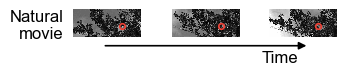

In [7]:
TRACE_MOVIE = '1_bushes'
PIXEL_MARK  = (0.72, 0.42)                # illustrative sampled location

with np.load(PATH_MOVIES / 'MovieFrames_full.npz') as z:
    FRAMES = {m: z[f'{m}|imgs'] for m in MOVIES}


def crop_landscape(img, aspect):
    h, w = img.shape
    keep = int(round(w / aspect))
    if keep >= h:
        return img
    top = (h - keep) // 2
    return img[top:top + keep]


Fig    = plt.figure(figsize=figsize_of('G'))
aspect = G_FRAME_W / (G_FRAME_Y[1] - G_FRAME_Y[0])
for x0, img in zip(G_FRAME_X, FRAMES[TRACE_MOVIE]):
    a = Fig.add_axes(rect_in('G', x0, G_FRAME_Y[0], x0 + G_FRAME_W, G_FRAME_Y[1]))
    a.imshow(crop_landscape(img, aspect), cmap='gray', vmin=0, vmax=255, aspect='auto',
             interpolation='none')
    a.set_xticks([]); a.set_yticks([])
    for sp in a.spines.values():
        sp.set_visible(False)
    a.plot(*PIXEL_MARK, marker='o', mfc='none', mec=COLOR_REF['red'], ms=4, mew=1.2,
           transform=a.transAxes, clip_on=False)

Fig.text(*point_in('G', *G_TEXT_XY), 'Natural\nmovie', ha='right', va='center',
         fontsize=12, linespacing=1.15)
xa0, ya = point_in('G', G_ARROW_X[0], G_ARROW_Y)
xa1, _  = point_in('G', G_ARROW_X[1], G_ARROW_Y)
Fig.add_artist(FancyArrowPatch((xa0, ya), (xa1, ya), transform=Fig.transFigure, color='k',
                               lw=1.2, arrowstyle='-|>', mutation_scale=11,
                               shrinkA=0, shrinkB=0))
Fig.text(*point_in('G', *G_TIME_XY), 'Time', ha='center', va='top', fontsize=12)

Fig.savefig(PATH_PDF / 'Fig3G_NatMovieFrames.pdf', transparent=True)
plt.show()

## Fig. 3H

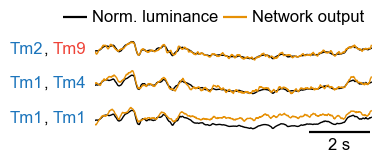

In [8]:
# OFF medulla: highest SNR, lowest-SNR same-polarity, lowest-SNR redundant pair
OFF = PAIRS['OFF Medulla']
snr = lambda l: SNR_PAIR[('OFF Medulla', l)]
TRACE_PAIRS = (max((l for l in OFF if pol_class(l) != 'R'), key=snr),
               min((l for l in OFF if pol_class(l) in ('D', 'S')), key=snr),
               min((l for l in OFF if pol_class(l) == 'R'), key=snr))
TRACE_DRAW = 0                            # filter realization shown
SD_FLOOR   = 0.25
HF_CUT     = 0.8                          # Hz
SCALE_BAR  = 2.0                          # s
SEG_GUARD  = K_LAGS * DT_FIXED            # s, decoder window after a pixel boundary

RESP = neuron_responses(TRACE_DRAW, np.sqrt(RESP_RATIO * response_scale()))
FITS = {pair: fit_pair(pair.split('-'), RESP) for pair in TRACE_PAIRS}


def hf_fraction(y, dt, cut=HF_CUT):
    # fraction of power above cut
    y = np.asarray(y, float) - np.mean(y)
    P = np.abs(np.fft.rfft(y * np.hanning(len(y)))) ** 2
    return float(P[np.fft.rfftfreq(len(y), dt) > cut].sum() / P.sum())


def pixel_window(i_movie, t_open, target):
    # one pixel's stretch of the held-out trace with median high-frequency content
    L     = T_MAX[i_movie] * TRACE_TIMEBASE / N_PIX
    t     = t_open + np.arange(len(target)) * DT_FIXED
    whole = []
    seg   = np.ceil(t_open / L) * L
    while seg + L <= t[-1]:
        m = (t >= seg + SEG_GUARD) & (t < seg + L)
        if m.sum() > 10:
            whole.append(dict(sd=float(np.std(target[m])), hf=hf_fraction(target[m], DT_FIXED),
                              seg=seg))
        seg += L
    keep = [c for c in whole if c['sd'] >= SD_FLOOR and np.isfinite(c['hf'])]
    med  = float(np.median([c['hf'] for c in keep]))
    seg  = min(keep, key=lambda c: abs(c['hf'] - med))['seg']
    return seg + SEG_GUARD - t_open, L - SEG_GUARD


i_movie = MOVIES.index(TRACE_MOVIE)
Fig     = plt.figure(figsize=figsize_of('H'))

_, n_train = FITS[TRACE_PAIRS[0]]
t_open = (MOVIE_CACHE[i_movie]['skip'] + n_train[i_movie]) * DT_FIXED
start, length = pixel_window(i_movie, t_open, held_out(TRACE_PAIRS[0], i_movie, RESP)[1])

for (lx0, lx1), tx, col, txt in zip(H_LEG_LINE, H_LEG_TEXT, (C_TRACE_STIM, C_TRACE_OUT),
                                    ('Norm. luminance', 'Network output')):
    p0, p1 = point_in('H', lx0, H_LEG_Y), point_in('H', lx1, H_LEG_Y)
    Fig.add_artist(Line2D([p0[0], p1[0]], [p0[1], p1[1]], transform=Fig.transFigure,
                          color=col, lw=1.6, solid_capstyle='butt'))
    Fig.text(*point_in('H', tx, H_LEG_Y), txt, ha='left', va='center', fontsize=12)

lo, hi, drawn = np.inf, -np.inf, []
for pair, (y_top, y_bot) in zip(TRACE_PAIRS, H_ROWS):
    a = Fig.add_axes(rect_in('H', H_TRACE_X[0], y_top, H_TRACE_X[1], y_bot))
    (w, S_mean, y_mean), _ = FITS[pair]
    S_te, target = held_out(pair, i_movie, RESP)
    decoded = (S_te - S_mean) @ w + y_mean
    t = t_open + np.arange(len(target)) * DT_FIXED
    m = (t >= t_open + start) & (t < t_open + start + length)
    a.plot(t[m], target[m],  color=C_TRACE_STIM, lw=1.0)
    a.plot(t[m], decoded[m], color=C_TRACE_OUT,  lw=1.0)
    a.set_xticks([]); a.set_yticks([])
    for sp in a.spines.values():
        sp.set_visible(False)
    lo = min(lo, target[m].min(), decoded[m].min())
    hi = max(hi, target[m].max(), decoded[m].max())
    drawn.append((a, pair))

t0, t1 = t_open + start, t_open + start + length
for (a, pair), (y_top, y_bot) in zip(drawn, H_ROWS):
    a.set_xlim(t0, t1)
    a.set_ylim(lo - 0.15 * (hi - lo), hi + 0.15 * (hi - lo))
    (_, na), (_, nb) = pair_tokens(pair)
    two_colour_text(Fig, point_in('H', H_LABEL_X, (y_top + y_bot) / 2.0),
                    [(na, COLOR_POLARITY[POLARITY_OF[na]]), (', ', 'k'),
                     (nb, COLOR_POLARITY[POLARITY_OF[nb]])], ha='right', va='center')

x1 = H_BAR_RIGHT
x0 = x1 - (H_TRACE_X[1] - H_TRACE_X[0]) * SCALE_BAR / (t1 - t0)
xb0, yb = point_in('H', x0, H_BAR_Y)
xb1, _  = point_in('H', x1, H_BAR_Y)
Fig.add_artist(Line2D([xb0, xb1], [yb, yb], transform=Fig.transFigure, color='k', lw=1.6,
                      solid_capstyle='butt'))
Fig.text((xb0 + xb1) / 2, yb - 0.035, f'{SCALE_BAR:g} s', ha='center', va='top', fontsize=12)

Fig.savefig(PATH_PDF / 'Fig3H_Traces_OFFMedulla.pdf', transparent=True)
plt.show()

## Fig. 3I, J

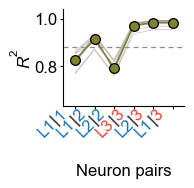

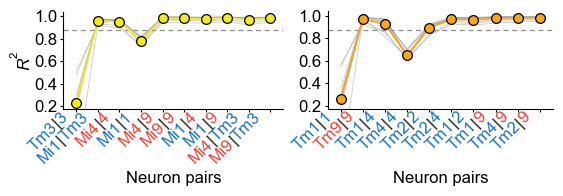

In [9]:
R2_GRAND = float(R2_MOVIE.mean())


def y_floor(keys):
    return min(R2_MOVIE[IDX[k]].mean() for k in keys) - 0.06


lamina  = [k for k in ALL_PAIRS if k[0] == 'Lamina']
medulla = [k for k in ALL_PAIRS if k[0] != 'Lamina']
Y_LIM  = {'Lamina':      (min(0.63, y_floor(lamina)), 1.04),
          'ON Medulla':  (min(0.23, y_floor(medulla)), 1.04),
          'OFF Medulla': (min(0.23, y_floor(medulla)), 1.04)}
Y_TICK = {'Lamina': [0.6, 0.8, 1.0], 'ON Medulla': [0.2, 0.4, 0.6, 0.8, 1.0],
          'OFF Medulla': [0.2, 0.4, 0.6, 0.8, 1.0]}
MOVIE_KW = dict(color='0.62', lw=0.6, alpha=0.55, zorder=1)
DASH_KW  = dict(color='0.55', lw=0.9, ls=(0, (4, 3)), zorder=0)


def draw_r2_axis(ax, circuit, ylabel=True):
    labs = SNR_ORDER[circuit]
    x    = np.arange(len(labs))
    rows = np.array([R2_MOVIE[IDX[(circuit, l)]] for l in labs])      # pairs x videos

    ax.axhline(R2_GRAND, **DASH_KW)
    ax.plot(x, rows, **MOVIE_KW)
    ax.plot(x, rows.mean(axis=1), color=COLOR_PATHWAY[circuit], marker='o', ms=7,
            mec='k', mew=0.9, lw=1.2, zorder=3)

    lim = Y_LIM[circuit]
    ax.set_yticks([t for t in Y_TICK[circuit] if lim[0] <= t <= lim[1]])
    ax.set_ylim(*lim)
    ax.set_xlim(-0.6, len(labs) - 0.4)
    ax.set_xticks(x)
    ax.set_xticklabels([])
    ax.tick_params(axis='x', length=2.5, pad=2)
    ax.tick_params(axis='y', length=2.5, pad=2)
    for xi, l in zip(x, labs):
        rotated_label(ax, xi, label_tokens(l), pad_pt=9.0)
    if ylabel:
        ax.set_ylabel('$R^2$', labelpad=0)


def x_caption(Fig, rect, text='Neuron pairs'):
    Fig.text(rect[0] + rect[2] / 2, 0.015, text, ha='center', va='bottom', fontsize=12)


Fig  = plt.figure(figsize=figsize_of('I'))
rect = rect_in('I', *AXES['I'])
draw_r2_axis(Fig.add_axes(rect), 'Lamina')
x_caption(Fig, rect)
Fig.savefig(PATH_PDF / 'Fig3I_R2_Lamina.pdf', transparent=True)
plt.show()

Fig = plt.figure(figsize=figsize_of('J'))
for circuit, key in (('ON Medulla', 'J1'), ('OFF Medulla', 'J2')):
    rect = rect_in('J', *AXES[key])
    draw_r2_axis(Fig.add_axes(rect), circuit, ylabel=(key == 'J1'))
    x_caption(Fig, rect)
Fig.savefig(PATH_PDF / 'Fig3J_R2_Medulla.pdf', transparent=True)
plt.show()

## Fig. 3K

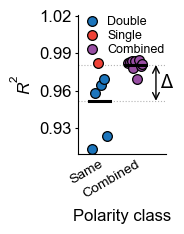

Delta = +3.01%, combined > same in 10/10 videos, one-sided Wilcoxon p = 0.000977


In [10]:
GROUPS = [('Same', ('D', 'S')), ('Combined', ('C',))]

POL = []
for _, classes in GROUPS:
    keys = [k for k in ALL_PAIRS if pol_class(k[1]) in classes]
    rows = np.array([R2_MOVIE[IDX[k]] for k in keys])            # (pairs, videos)
    POL.append(dict(keys=keys, per_movie=rows, means=rows.mean(axis=1)))

Fig = plt.figure(figsize=figsize_of('K'))
ax  = Fig.add_axes(rect_in('K', *AXES['K']))

means = []
for gi, g in enumerate(POL):
    xj = gi + np.linspace(-0.20, 0.20, g['means'].size)
    for x0, y0, k0 in zip(xj, g['means'], g['keys']):
        ax.plot(x0, y0, 'o', markersize=7, markerfacecolor=COLOR_CLASS[pol_class(k0[1])],
                markeredgecolor='k', markeredgewidth=0.9, zorder=3)
    m = float(g['means'].mean())
    means.append(m)
    ax.axhline(m, color='0.7', lw=0.8, ls=':', zorder=1)
    ax.plot([gi - 0.30, gi + 0.30], [m] * 2, '-', color='k', lw=2.2, zorder=4)

span_pt = abs(ax.transData.transform((0, means[1]))[1]
              - ax.transData.transform((0, means[0]))[1])
ax.annotate('', xy=(1.58, means[1]), xytext=(1.58, means[0]),
            arrowprops=dict(arrowstyle='<->', color='k', lw=1.0,
                            mutation_scale=min(12.0, 0.34 * span_pt),
                            shrinkA=0, shrinkB=0))
ax.text(1.70, 0.5 * (means[0] + means[1]), r'$\Delta$', fontsize=13, va='center', ha='left')

ax.set_xlim(-0.60, 1.85)
ax.set_xticks([0, 1])
ax.set_xticklabels([n for n, _ in GROUPS], fontsize=10, rotation=30, ha='right',
                   rotation_mode='anchor')
ax.set_xlabel('Polarity class', labelpad=6)
ax.set_ylabel('$R^2$')
ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(nbins=4))
y_lo, y_hi = ax.get_ylim()
ax.set_ylim(y_lo, y_lo + (y_hi - y_lo) * 1.42)
ax.tick_params(axis='x', length=0)
ax.tick_params(axis='y', length=2.5, pad=2)
ax.legend(handles=[Line2D([], [], ls='none', marker='o', markersize=7,
                          markerfacecolor=COLOR_CLASS[cl], markeredgecolor='k',
                          markeredgewidth=0.9, label=CLASS_NAME[cl]) for cl in 'DSC'],
          loc='upper left', frameon=False, fontsize=9, handletextpad=0.2,
          labelspacing=0.15, borderpad=0.0, borderaxespad=0.1)
Fig.savefig(PATH_PDF / 'Fig3K_R2_PolarityClass.pdf', transparent=True)
plt.show()

same, comb = POL
gap   = comb['per_movie'].mean(axis=0) - same['per_movie'].mean(axis=0)
delta = 100.0 * (comb['means'].mean() / same['means'].mean() - 1.0)
print(f'Delta = {delta:+.2f}%, combined > same in {int((gap > 0).sum())}/{N_MOVIES} videos, '
      f'one-sided Wilcoxon p = {wilcoxon(gap, alternative="greater").pvalue:.3g}')

## Fig. S4

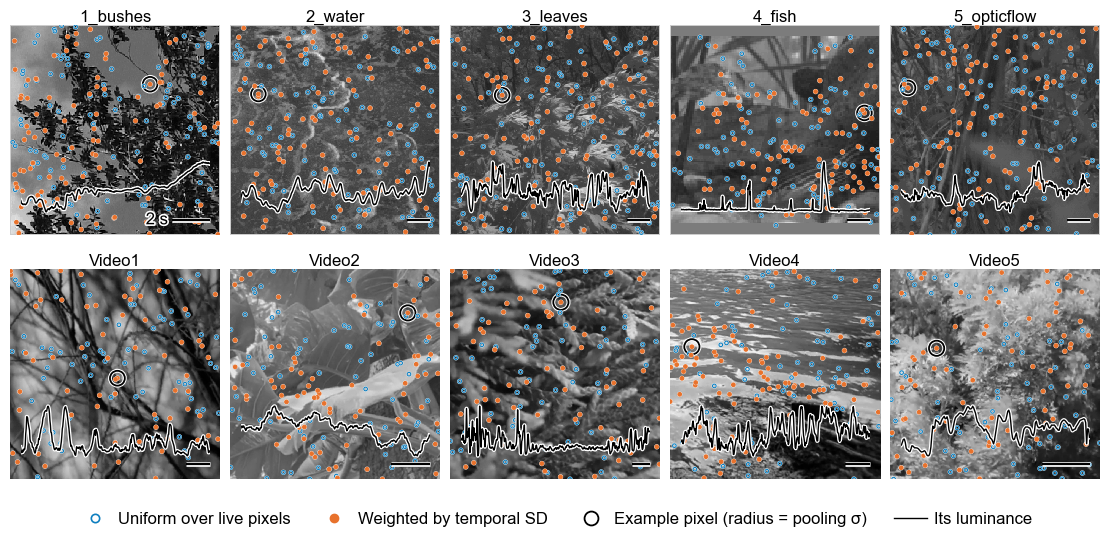

In [11]:
C_UNI, C_WGT = '#0F7FBF', '#E8722C'       # uniform / SD-weighted sampling
MS_PIX    = 2.6
PIX_SIDE  = 2.1                           # inches per frame
PIX_FRAME = 1
PIX_BAR   = 2.0                           # s

FRAMES_FULL = {m: FRAMES[m][PIX_FRAME] for m in MOVIES}


def square_crop(movie):
    # largest square holding the most sampled locations
    img  = FRAMES_FULL[movie]
    h, w = img.shape
    side = min(h, w)
    yx   = META[f'{movie}|yx']
    axis, n = (0, h) if h > w else (1, w)
    offs = np.arange(n - side + 1)
    inside = [((yx[:, axis] >= o) & (yx[:, axis] < o + side)).sum() for o in offs]
    best = offs[np.flatnonzero(inside == np.max(inside))]
    o    = int(best[np.argmin(np.abs(best - (n - side) / 2))])
    return (o, 0, side) if h > w else (0, o, side)


def example_pixel(movie, yx, side):
    # SD-weighted location in the upper part of the crop with median high-frequency content
    X    = np.loadtxt(PATH_TRACES / f'TracesNatural{movie}_live.txt')          # frames x pixels
    fps  = float(META[f'{movie}|fps'])
    m    = 2.0 * float(META[f'{movie}|sigma_px'])
    ok   = (yx[:, 0] >= m) & (yx[:, 0] < 0.55 * side) & (yx[:, 1] >= m) & (yx[:, 1] < side - m)
    cand = np.flatnonzero((META[f'{movie}|kind'] == 1) & ok)
    hf   = np.array([hf_fraction(X[:, j], 1.0 / fps) for j in cand])
    j    = cand[np.argmin(np.abs(hf - np.median(hf)))]
    return j, X[:, j], fps


n_col = 5
n_row = int(np.ceil(N_MOVIES / n_col))
gap_x, top, gap_y, bottom = 0.10, 0.30, 0.34, 0.62           # inches
W = n_col * PIX_SIDE + (n_col - 1) * gap_x
H = top + n_row * PIX_SIDE + (n_row - 1) * gap_y + bottom
Fig  = plt.figure(figsize=(W, H))
halo = [pe.withStroke(linewidth=1.2, foreground='white')]
for k, movie in enumerate(MOVIES):
    r, c = divmod(k, n_col)
    x0 = c * (PIX_SIDE + gap_x)
    y0 = H - top - r * (PIX_SIDE + gap_y) - PIX_SIDE
    a  = Fig.add_axes([x0 / W, y0 / H, PIX_SIDE / W, PIX_SIDE / H])
    top_px, left_px, side = square_crop(movie)
    img = FRAMES_FULL[movie][top_px:top_px + side, left_px:left_px + side]
    a.imshow(img, cmap='gray', vmin=0, vmax=255, interpolation='none',
             extent=(-0.5, side - 0.5, side - 0.5, -0.5))
    a.set_xlim(-0.5, side - 0.5); a.set_ylim(side - 0.5, -0.5)
    a.set_xticks([]); a.set_yticks([])
    for sp in a.spines.values():
        sp.set_visible(False)

    yx     = META[f'{movie}|yx'].astype(float) - (top_px, left_px)
    inside = (yx[:, 0] >= 0) & (yx[:, 0] < side) & (yx[:, 1] >= 0) & (yx[:, 1] < side)
    kind   = META[f'{movie}|kind']
    for sel, col, fc in [(kind == 0, C_UNI, 'none'), (kind == 1, C_WGT, C_WGT)]:
        sel = sel & inside
        a.plot(yx[sel, 1], yx[sel, 0], ls='none', marker='o', ms=MS_PIX,
               markerfacecolor=fc, markeredgecolor=col, markeredgewidth=0.8,
               path_effects=halo)

    j, y, fps = example_pixel(movie, yx, side)
    sig = float(META[f'{movie}|sigma_px'])
    a.add_patch(plt.Circle((yx[j, 1], yx[j, 0]), sig, fill=False, ec='k', lw=1.3,
                           path_effects=[pe.withStroke(linewidth=2.8, foreground='white')]))

    t  = np.arange(len(y)) / fps
    ta = a.inset_axes([0.05, 0.10, 0.90, 0.26])
    ta.patch.set_visible(False); ta.axis('off')
    ta.plot(t, y, color='k', lw=1.0,
            path_effects=[pe.withStroke(linewidth=2.8, foreground='white')])
    ta.set_xlim(0, t[-1])
    lo, hi = y.min(), y.max()
    ta.set_ylim(lo - 0.05 * (hi - lo), hi + 0.05 * (hi - lo))
    bar_y = -0.10
    ta.plot([t[-1] - PIX_BAR, t[-1]], [bar_y, bar_y], color='k', lw=1.6,
            solid_capstyle='butt', transform=ta.get_xaxis_transform(), clip_on=False,
            path_effects=[pe.withStroke(linewidth=3.4, foreground='white')])
    a.set_title(movie, fontsize=12, pad=3)
    if k == 0:
        ta.text(t[-1] - PIX_BAR - 0.02 * t[-1], bar_y, f'{PIX_BAR:g} s', ha='right', va='center',
                fontsize=12, transform=ta.get_xaxis_transform(), clip_on=False,
                path_effects=[pe.withStroke(linewidth=2.4, foreground='white')])

h = [Line2D([], [], ls='none', marker='o', ms=6, markerfacecolor='none',
            markeredgecolor=C_UNI, markeredgewidth=1.2, label='Uniform over live pixels'),
     Line2D([], [], ls='none', marker='o', ms=6, markerfacecolor=C_WGT,
            markeredgecolor=C_WGT, label='Weighted by temporal SD'),
     Line2D([], [], ls='none', marker='o', ms=10, markerfacecolor='none',
            markeredgecolor='k', markeredgewidth=1.3, label='Example pixel (radius = pooling σ)'),
     Line2D([], [], color='k', lw=1.0, label='Its luminance')]
Fig.legend(handles=h, loc='lower center', ncol=4, frameon=False, fontsize=12,
           bbox_to_anchor=(0.5, 0.0), handletextpad=0.4, columnspacing=1.6)
Fig.savefig(PATH_PDF / 'FigS4_SampledPixels.pdf', transparent=True)
plt.show()